In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose # для декомпозиции временных рядов
from statsmodels.tsa.stattools import adfuller #  для теста Дики-Фуллера на стационарность



# Данные из таблицы
data = {
    'Вариант 1': [13.5, 12.7, 12, 11.9, 11.5, 11.2, 10.8, 10.7, 10.6, 10.5],
    'Вариант 2': [251, 249, 248, 246, 242, 239, 235, 230, 228, 225],
    'Вариант 3': [0.91, 0.87, 0.85, 0.82, 0.79, 0.75, 0.7, 0.66, 0.62, 0.6],
    'Вариант 4': [2.54, 2.5, 2.45, 2.4, 2.37, 2.3, 2.27, 2.19, 2.05, 2],
    'Вариант 5': [6.3, 6.21, 6.15, 6, 5.8, -5.45, 5.05, 4.85, 4.5, 4.2],
    'Вариант 6': [18.2, 17.5, 17.1, 16.8, 16.1, 15.7, 15.2, 14.5, 14.3, 14],
    'Вариант 7': [134, 130, 128, 126, 122, 120, 117, 112, 108, 105],
    'Вариант 8': [64, 61, 58, 52, 49, 45, 40, 37, 34, 30],
    'Вариант 9': [4.25, 4.2, 4.18, 4.11, 4.05, 4, 3.91, 3.85, 3.77, 3.7],
    'Вариант 10': [1.8, 1.78, 1.7, 1.64, 1.59, 1.51, 1.45, 1.42, 1.4, 1.37]
}

df = pd.DataFrame(data) # создаем массив значений
years = np.arange(1, 11) # создаем массив порядка
df.index = years # подвязываем массив значений и массив порядка

In [4]:
def analyze_trend(series, name):
    print(f"\nАнализ для {name}")
    
    # Тест Дики-Фуллера на стационарность
    result = adfuller(series) # выполняется тест Дики-Фуллера
    print(f'ADF Statistic: {result[0]}') # основное значение тестовой статистики, которое сравнивается с критическими значениями
    print(f'p-value: {result[1]}') # показывает вероятность получить такие результаты, если нулевая гипотеза верна
    if result[1] > 0.05:
        print("Ряд нестационарен - есть тренд")
    else:
        print("Ряд стационарен - тренд отсутствует")
    
    # Визуализация
    plt.figure(figsize=(10, 4))
    plt.plot(series, label='Фактические данные')
    plt.title(f'Временной ряд для {name}')
    plt.xlabel('Год')
    plt.ylabel('Значение')
    plt.legend()
    plt.show()
    
    # Построение линейного тренда
    if result[1] > 0.05:  # Если есть тренд
        coefficients = np.polyfit(series.index, series.values, 1)
        trend_line = np.poly1d(coefficients)
        print(f"Трендовая модель: y = {coefficients[0]:.4f}x + {coefficients[1]:.4f}")
        
        plt.figure(figsize=(10, 4))
        plt.plot(series, label='Фактические данные')
        plt.plot(series.index, trend_line(series.index), 'r--', label='Тренд')
        plt.title(f'Трендовая модель для {name}')
        plt.xlabel('Год')
        plt.ylabel('Значение')
        plt.legend()
        plt.show()
    else:
        print("Тренд не обнаружен, модель не строится")


Анализ для Вариант 1
ADF Statistic: -8.715939870322726
p-value: 3.488353425570833e-14
Ряд стационарен - тренд отсутствует


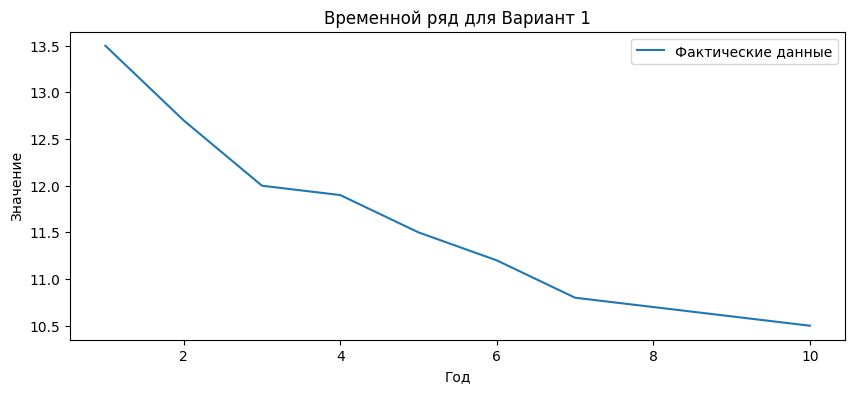

Тренд не обнаружен, модель не строится

Анализ для Вариант 2
ADF Statistic: -2.6048838326086337
p-value: 0.0919920738978976
Ряд нестационарен - есть тренд


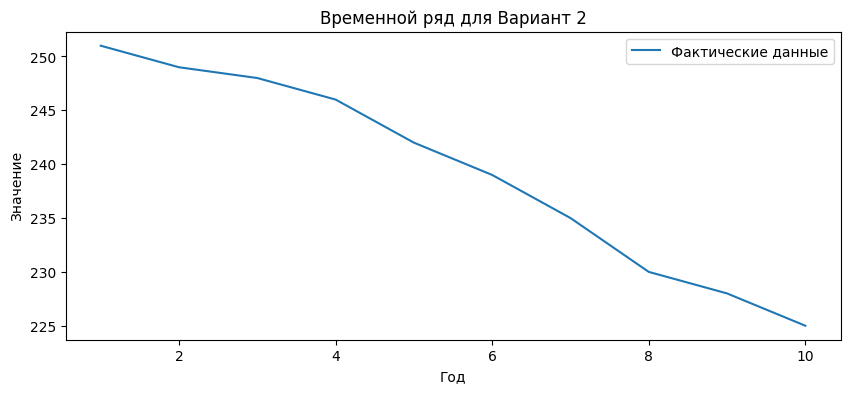

Трендовая модель: y = -3.0727x + 256.2000


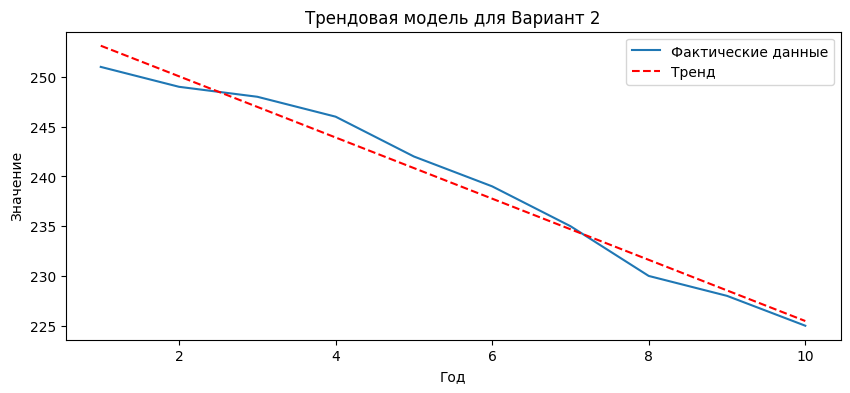


Анализ для Вариант 3
ADF Statistic: -1.4357252919478065
p-value: 0.5650342571668016
Ряд нестационарен - есть тренд


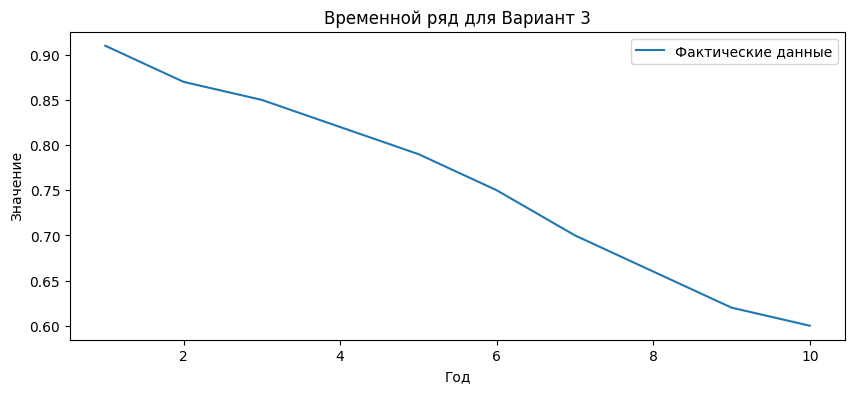

Трендовая модель: y = -0.0357x + 0.9533


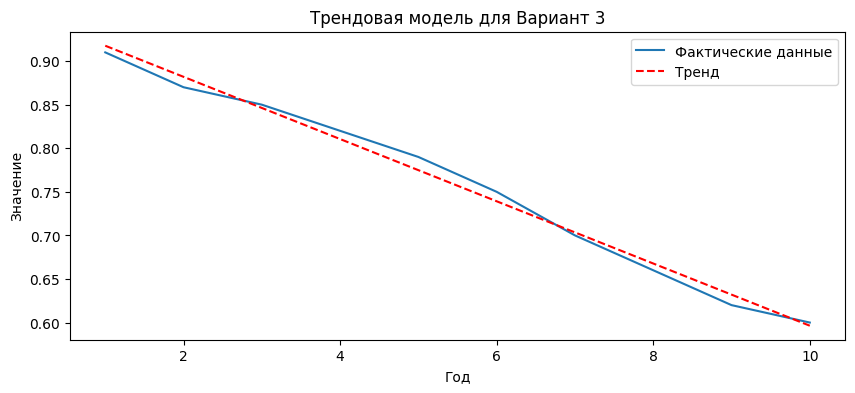


Анализ для Вариант 4
ADF Statistic: 1.7234536327483976
p-value: 0.9981844778152682
Ряд нестационарен - есть тренд


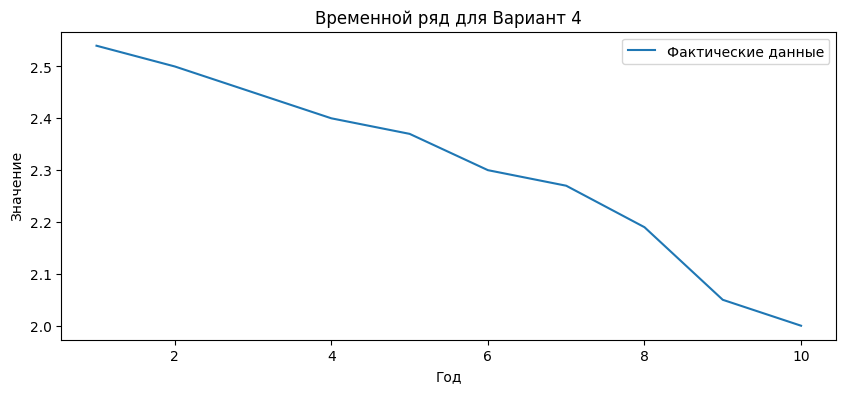

Трендовая модель: y = -0.0592x + 2.6327


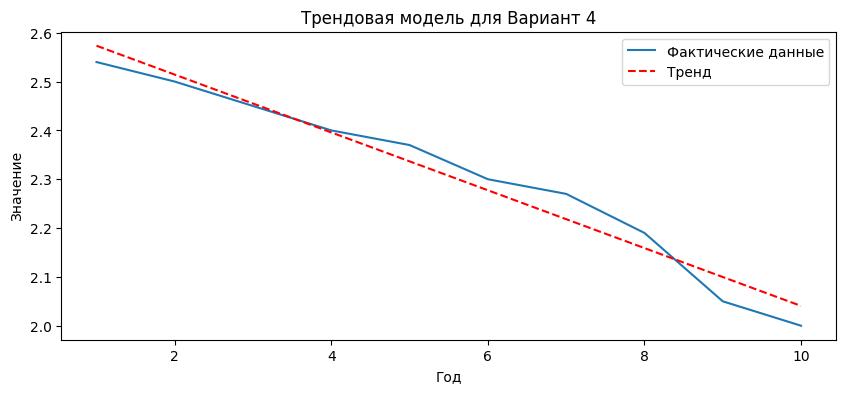


Анализ для Вариант 5
ADF Statistic: -2.9033534582421607
p-value: 0.04495942332146158
Ряд стационарен - тренд отсутствует


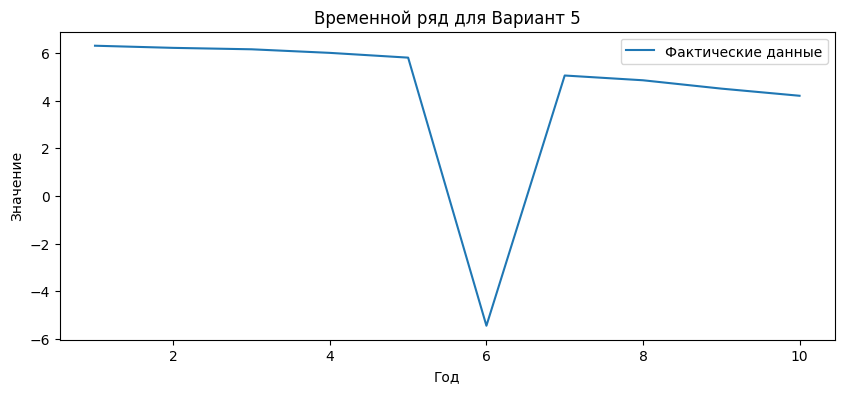

Тренд не обнаружен, модель не строится

Анализ для Вариант 6
ADF Statistic: -1.4678570892175988
p-value: 0.5493478534928977
Ряд нестационарен - есть тренд


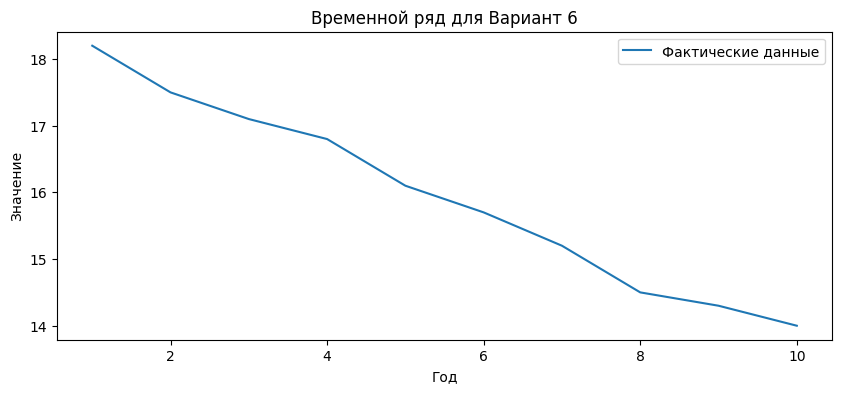

Трендовая модель: y = -0.4752x + 18.5533


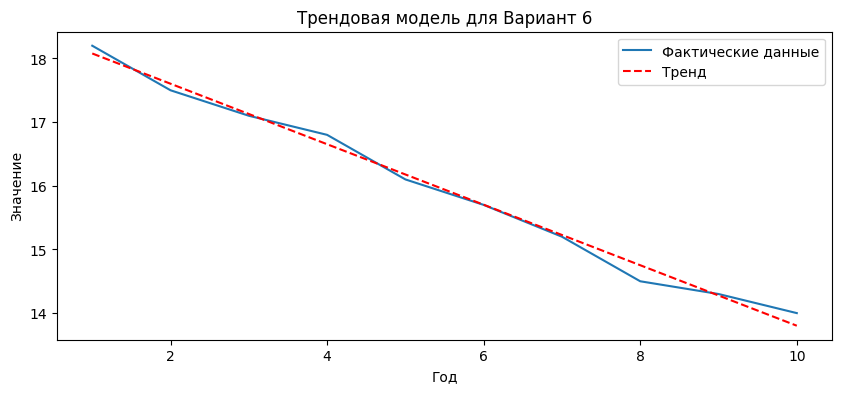


Анализ для Вариант 7
ADF Statistic: 2.797282635546534
p-value: 1.0
Ряд нестационарен - есть тренд


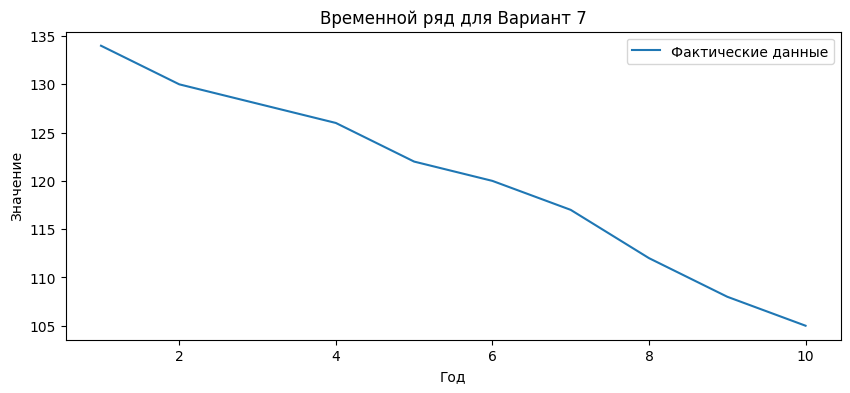

Трендовая модель: y = -3.1758x + 137.6667


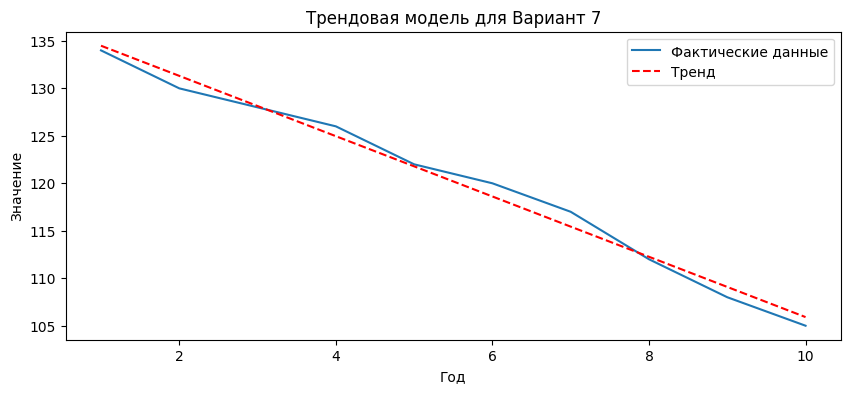


Анализ для Вариант 8
ADF Statistic: -1.0671269323674744
p-value: 0.7280017431527119
Ряд нестационарен - есть тренд


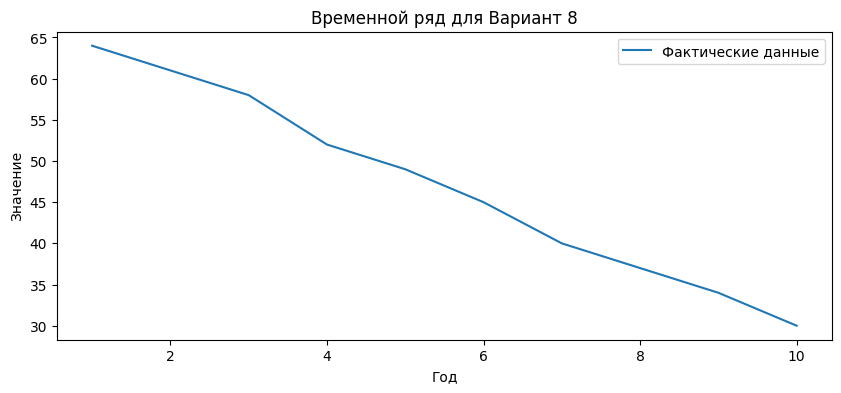

Трендовая модель: y = -3.8788x + 68.3333


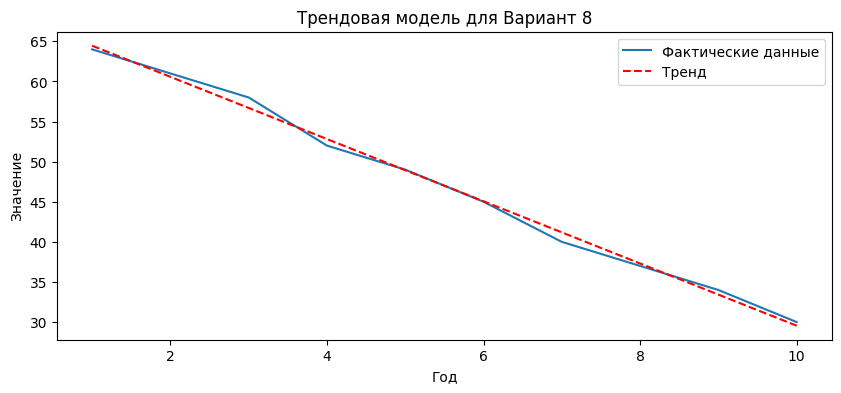


Анализ для Вариант 9
ADF Statistic: -0.36939606836434785
p-value: 0.9150845072246363
Ряд нестационарен - есть тренд


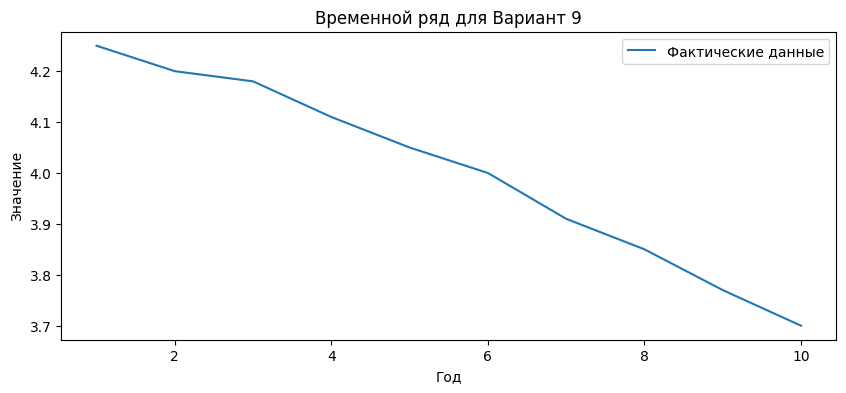

Трендовая модель: y = -0.0622x + 4.3440


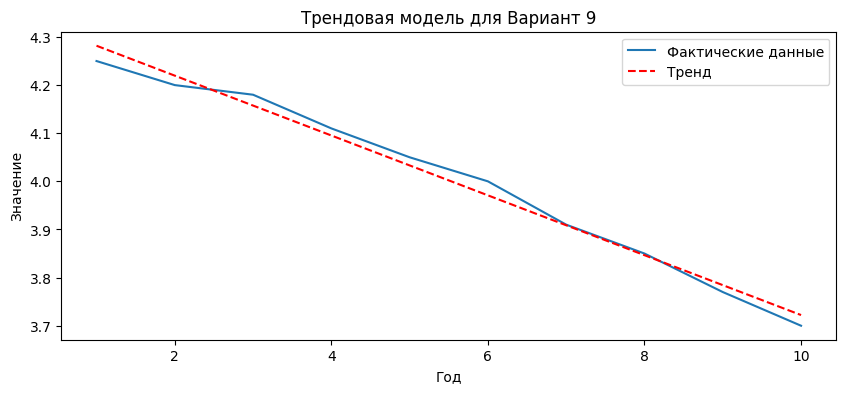


Анализ для Вариант 10
ADF Statistic: -2.7746201099157193
p-value: 0.06199155458033299
Ряд нестационарен - есть тренд


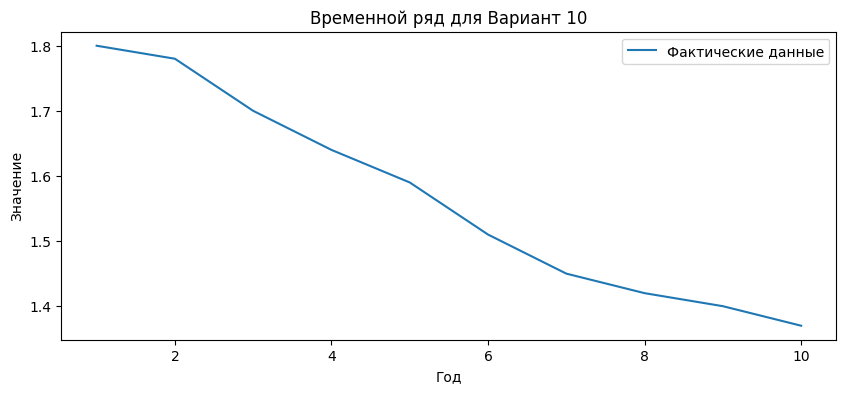

Трендовая модель: y = -0.0520x + 1.8520


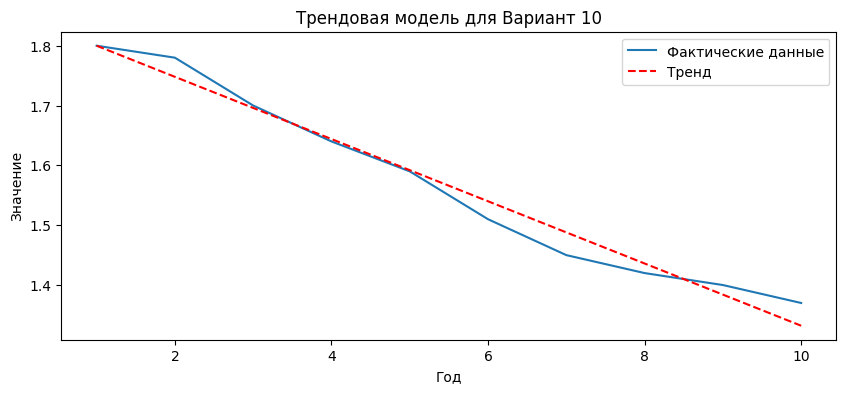

In [5]:
for col in df.columns:
    analyze_trend(df[col], col)